## ✈ Flight Schedule and Gate Assignment Optimizer ✈

In this project, we will find a feasible assignment of flights to airport gates while minimizing conflicts, unnecessary gate changes, or passenger walking distance.
- Methods: Linear programming or constraint optimization with Python and OR-Tools.
- Output: A gate schedule, conflict alerts, and a comparison between the original and optimized schedules.
- Why it's valuable: Demonstrates mathematical optimization, resource allocation, and operational decision-making.

In [8]:
pip install ortools

### 1. Generate Synthetic Flight & Gate Data
We will define a set of flights with specific arrival/departure times, sizes, and passenger volumes, along with airport gates of various sizes located at different distances from the main terminal exit.

In [9]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# 1. Define Airport Gates
gates = pd.DataFrame({
    'Gate_ID': [f'Gate_{i}' for i in range(1, 6)],
    'Max_Size': ['Heavy', 'Heavy', 'Medium', 'Medium', 'Small'], # Gate capacity
    'Walking_Distance': [50, 100, 200, 250, 400] # Distance in meters from terminal hall
})

# 2. Define Flights (Times represented in minutes from midnight, e.g., 08:00 = 480)
flights = pd.DataFrame({
    'Flight_ID': [f'FL_{100+i}' for i in range(10)],
    'Arrival': [480, 500, 520, 600, 620, 700, 710, 800, 820, 900],
    'Departure': [540, 580, 590, 660, 700, 760, 790, 880, 910, 980],
    'Size': ['Heavy', 'Medium', 'Small', 'Heavy', 'Medium', 'Heavy', 'Small', 'Medium', 'Heavy', 'Small'],
    'Passengers': [250, 150, 80, 280, 160, 260, 70, 180, 290, 90],
    'Original_Gate': ['Gate_1', 'Gate_1', 'Gate_2', 'Gate_2', 'Gate_3', 'Gate_4', 'Gate_4', 'Gate_5', 'Gate_1', 'Gate_5']
})

display(gates)
display(flights)

,Gate_ID,Max_Size,Walking_Distance
0,Gate_1,Heavy,50
1,Gate_2,Heavy,100
2,Gate_3,Medium,200
3,Gate_4,Medium,250
4,Gate_5,Small,400


,Flight_ID,Arrival,Departure,Size,Passengers,Original_Gate
0,FL_100,480,540,Heavy,250,Gate_1
1,FL_101,500,580,Medium,150,Gate_1
2,FL_102,520,590,Small,80,Gate_2
3,FL_103,600,660,Heavy,280,Gate_2
4,FL_104,620,700,Medium,160,Gate_3
5,FL_105,700,760,Heavy,260,Gate_4
6,FL_106,710,790,Small,70,Gate_4
7,FL_107,800,880,Medium,180,Gate_5
8,FL_108,820,910,Heavy,290,Gate_1
9,FL_109,900,980,Small,90,Gate_5


### 2. Formulate and Solve the Gate Assignment Problem
We will use OR-Tools CP-SAT solver to map flights to gates such that:
- **No overlapping assignments** exist for any gate.
- **Size constraint**: A flight's size cannot exceed its assigned gate's maximum capacity size (`Heavy` fits in `Heavy` gates; `Medium` fits in `Medium`/`Heavy` gates; `Small` fits in all gates).
- **Objective**: Minimize the total passenger walking distance (Sum of passengers × gate walking distance).

In [10]:
from ortools.sat.python import cp_model

# Size hierarchy mapping for validation
size_map = {'Small': 1, 'Medium': 2, 'Heavy': 3}

model = cp_model.CpModel()

num_flights = len(flights)
num_gates = len(gates)

# Decision variables: x[f, g] = 1 if flight f is assigned to gate g, else 0
x = {}
for f in range(num_flights):
    for g in range(num_gates):
        x[f, g] = model.NewBoolVar(f'x_{f}_{g}')

# Constraint 1: Every flight must be assigned to exactly one gate
for f in range(num_flights):
    model.Add(sum(x[f, g] for g in range(num_gates)) == 1)

# Constraint 2: Size compatibility
for f in range(num_flights):
    f_size_val = size_map[flights.iloc[f]['Size']]
    for g in range(num_gates):
        g_size_val = size_map[gates.iloc[g]['Max_Size']]
        if f_size_val > g_size_val:
            # If flight size exceeds gate capacity, assignment is impossible (must be 0)
            model.Add(x[f, g] == 0)

# Constraint 3: No time overlaps at the same gate
for g in range(num_gates):
    for f1 in range(num_flights):
        for f2 in range(f1 + 1, num_flights):
            # Check if times overlap
            overlap = not (flights.iloc[f1]['Departure'] <= flights.iloc[f2]['Arrival'] or
                           flights.iloc[f2]['Departure'] <= flights.iloc[f1]['Arrival'])
            if overlap:
                # If they overlap, they both cannot be assigned to gate g
                model.Add(x[f1, g] + x[f2, g] <= 1)

# Objective: Minimize total passenger walking distance
objective = []
for f in range(num_flights):
    passengers = flights.iloc[f]['Passengers']
    for g in range(num_gates):
        dist = gates.iloc[g]['Walking_Distance']
        objective.append(x[f, g] * passengers * dist)

model.Minimize(sum(objective))

# Solve the model
solver = cp_model.CpSolver()
status = solver.Solve(model)

if status == cp_model.OPTIMAL or status == cp_model.FEASIBLE:
    optimized_assignments = []
    for f in range(num_flights):
        assigned_gate = None
        for g in range(num_gates):
            if solver.Value(x[f, g]) == 1:
                assigned_gate = gates.iloc[g]['Gate_ID']
                break
        optimized_assignments.append(assigned_gate)

    flights['Optimized_Gate'] = optimized_assignments
    print("Optimization complete! Optimal gate assignments determined successfully.")
else:
    print("No feasible solution found.")

Optimization complete! Optimal gate assignments determined successfully.


### 2.1. Add Gate Maintenance Constraints
Let's define maintenance windows where certain gates are completely unavailable for operations, then add these operational constraints to our solver model.

In [11]:
# Define Gate Maintenance Windows (expressed in minutes from midnight)
# e.g., Gate_1 is closed for maintenance from 08:00 to 09:30 (480 to 570 mins)
maintenance_windows = [
    {'Gate_ID': 'Gate_1', 'Start': 480, 'End': 570},
    {'Gate_ID': 'Gate_2', 'Start': 600, 'End': 720}
]

# Initialize model again with the new constraint
model_m = cp_model.CpModel()

x_m = {}
for f in range(num_flights):
    for g in range(num_gates):
        x_m[f, g] = model_m.NewBoolVar(f'x_m_{f}_{g}')

# Constraint 1: Every flight must be assigned to exactly one gate
for f in range(num_flights):
    model_m.Add(sum(x_m[f, g] for g in range(num_gates)) == 1)

# Constraint 2: Size compatibility
for f in range(num_flights):
    f_size_val = size_map[flights.iloc[f]['Size']]
    for g in range(num_gates):
        g_size_val = size_map[gates.iloc[g]['Max_Size']]
        if f_size_val > g_size_val:
            model_m.Add(x_m[f, g] == 0)

# Constraint 3: No time overlaps at the same gate
for g in range(num_gates):
    for f1 in range(num_flights):
        for f2 in range(f1 + 1, num_flights):
            overlap = not (flights.iloc[f1]['Departure'] <= flights.iloc[f2]['Arrival'] or
                           flights.iloc[f2]['Departure'] <= flights.iloc[f1]['Arrival'])
            if overlap:
                model_m.Add(x_m[f1, g] + x_m[f2, g] <= 1)

# Constraint 4: Gate Maintenance Windows (No flight can use a gate during maintenance)
for maint in maintenance_windows:
    g_idx = gates[gates['Gate_ID'] == maint['Gate_ID']].index[0]
    for f in range(num_flights):
        f_arr = flights.iloc[f]['Arrival']
        f_dep = flights.iloc[f]['Departure']

        # Check if the flight's schedule overlaps with the maintenance window
        overlap_with_maint = not (f_dep <= maint['Start'] or f_arr >= maint['End'])
        if overlap_with_maint:
            # If it overlaps, the flight cannot be assigned to this gate
            model_m.Add(x_m[f, g_idx] == 0)

# Objective: Minimize total passenger walking distance
objective_m = []
for f in range(num_flights):
    passengers = flights.iloc[f]['Passengers']
    for g in range(num_gates):
        dist = gates.iloc[g]['Walking_Distance']
        objective_m.append(x_m[f, g] * passengers * dist)

model_m.Minimize(sum(objective_m))

# Solve the model with maintenance constraints
solver_m = cp_model.CpSolver()
status_m = solver_m.Solve(model_m)

if status_m == cp_model.OPTIMAL or status_m == cp_model.FEASIBLE:
    optimized_assignments_m = []
    for f in range(num_flights):
        assigned_gate = None
        for g in range(num_gates):
            if solver_m.Value(x_m[f, g]) == 1:
                assigned_gate = gates.iloc[g]['Gate_ID']
                break
        optimized_assignments_m.append(assigned_gate)

    flights['Optimized_Gate_With_Maint'] = optimized_assignments_m
    print("Optimization complete! Optimal gate assignments with maintenance windows computed.")
else:
    print("No feasible solution found with maintenance constraints.")

Optimization complete! Optimal gate assignments with maintenance windows computed.


In [12]:
# Compare results with and without maintenance constraints
opt_dist_m = calculate_metrics(flights, 'Optimized_Gate_With_Maint')

print("\n--- Performance Comparison ---")
print(f"Original Schedule Walking Distance: {orig_dist:,} meters")
print(f"Optimized Schedule (No Maint) Walking Distance: {opt_dist:,} meters")
print(f"Optimized Schedule (With Maint) Walking Distance: {opt_dist_m:,} meters")

display(flights[['Flight_ID', 'Arrival', 'Departure', 'Size', 'Passengers', 'Original_Gate', 'Optimized_Gate', 'Optimized_Gate_With_Maint']])


--- Performance Comparison ---
Original Schedule Walking Distance: 293,000 meters
Optimized Schedule (No Maint) Walking Distance: 135,000 meters
Optimized Schedule (With Maint) Walking Distance: 189,500 meters


,Flight_ID,Arrival,Departure,Size,Passengers,Original_Gate,Optimized_Gate,Optimized_Gate_With_Maint
0,FL_100,480,540,Heavy,250,Gate_1,Gate_1,Gate_2
1,FL_101,500,580,Medium,150,Gate_1,Gate_2,Gate_3
2,FL_102,520,590,Small,80,Gate_2,Gate_3,Gate_4
3,FL_103,600,660,Heavy,280,Gate_2,Gate_1,Gate_1
4,FL_104,620,700,Medium,160,Gate_3,Gate_2,Gate_3
5,FL_105,700,760,Heavy,260,Gate_4,Gate_1,Gate_1
6,FL_106,710,790,Small,70,Gate_4,Gate_2,Gate_3
7,FL_107,800,880,Medium,180,Gate_5,Gate_2,Gate_2
8,FL_108,820,910,Heavy,290,Gate_1,Gate_1,Gate_1
9,FL_109,900,980,Small,90,Gate_5,Gate_2,Gate_2


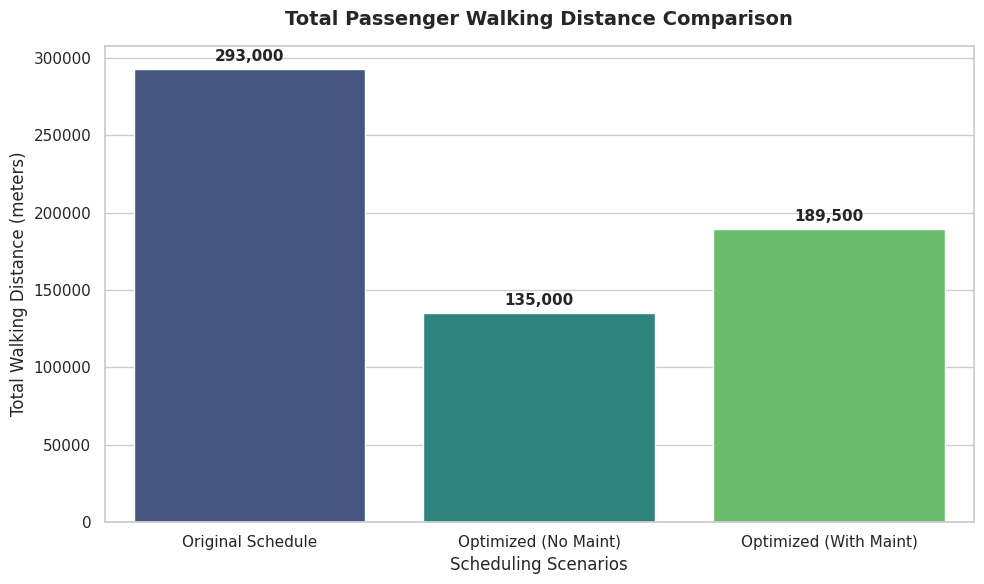

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
scenarios = ['Original Schedule', 'Optimized (No Maint)', 'Optimized (With Maint)']
distances = [orig_dist, opt_dist, opt_dist_m]

# Create the plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=scenarios, y=distances, palette='viridis', hue=scenarios, legend=False)

# Customize chart
plt.title('Total Passenger Walking Distance Comparison', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Total Walking Distance (meters)', fontsize=12)
plt.xlabel('Scheduling Scenarios', fontsize=12)

# Annotate bar values
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='semibold')

plt.tight_layout()
plt.show()

### 3. Identify Original Conflict Alerts and Analyze Results
We will inspect the original flight schedule to identify any overlaps or size mismatches, and compare the walking efficiency between the unoptimized baseline and our optimized outcome.

In [14]:
# Detect conflicts in original schedule
original_conflicts = []
for i, f1 in flights.iterrows():
    for j, f2 in flights.iterrows():
        if i < j and f1['Original_Gate'] == f2['Original_Gate']:
            overlap = not (f1['Departure'] <= f2['Arrival'] or f2['Departure'] <= f1['Arrival'])
            if overlap:
                original_conflicts.append(f"Conflict: {f1['Flight_ID']} and {f2['Flight_ID']} overlap at {f1['Original_Gate']}")

print("--- Original Schedule Conflict Alerts ---")
if original_conflicts:
    for alert in original_conflicts:
        print(alert)
else:
    print("No conflicts in original schedule.")

# Helper function to calculate total walking distance
def calculate_metrics(df, gate_col):
    total_dist = 0
    for _, row in df.iterrows():
        gate_info = gates[gates['Gate_ID'] == row[gate_col]].iloc[0]
        total_dist += row['Passengers'] * gate_info['Walking_Distance']
    return total_dist

orig_dist = calculate_metrics(flights, 'Original_Gate')
opt_dist = calculate_metrics(flights, 'Optimized_Gate')

print("\n--- Performance Comparison ---")
print(f"Original Schedule Passenger Walking Distance: {orig_dist:,} meters")
print(f"Optimized Schedule Passenger Walking Distance: {opt_dist:,} meters")
print(f"Reduction in Passenger Walking Distance: {((orig_dist - opt_dist)/orig_dist)*100:.1f}%")

display(flights[['Flight_ID', 'Arrival', 'Departure', 'Size', 'Passengers', 'Original_Gate', 'Optimized_Gate']])

--- Original Schedule Conflict Alerts ---
Conflict: FL_100 and FL_101 overlap at Gate_1
Conflict: FL_105 and FL_106 overlap at Gate_4

--- Performance Comparison ---
Original Schedule Passenger Walking Distance: 293,000 meters
Optimized Schedule Passenger Walking Distance: 135,000 meters
Reduction in Passenger Walking Distance: 53.9%


,Flight_ID,Arrival,Departure,Size,Passengers,Original_Gate,Optimized_Gate
0,FL_100,480,540,Heavy,250,Gate_1,Gate_1
1,FL_101,500,580,Medium,150,Gate_1,Gate_2
2,FL_102,520,590,Small,80,Gate_2,Gate_3
3,FL_103,600,660,Heavy,280,Gate_2,Gate_1
4,FL_104,620,700,Medium,160,Gate_3,Gate_2
5,FL_105,700,760,Heavy,260,Gate_4,Gate_1
6,FL_106,710,790,Small,70,Gate_4,Gate_2
7,FL_107,800,880,Medium,180,Gate_5,Gate_2
8,FL_108,820,910,Heavy,290,Gate_1,Gate_1
9,FL_109,900,980,Small,90,Gate_5,Gate_2
